# Assignment 3 - Sampling Distributions and Estimation

Daniel Munteanu, Josip Brljevic, Luca Mouawad, Zygmunt Tadeusz Kwasniewicz

In [1]:
from statsmodels.stats.proportion import proportion_confint
from IPython.display import display, Markdown
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math

# Part 1 — Sampling distributions and the CLT
#### Restoration time in a service system is modelled as exponential with population mean and standard deviation $\mu=\sigma=60$ minutes. Use this known population model and NumPy's random generator with seed 2026 and at least 20,000 repetitions per sample size.

### a) Simulate samples for $n=1,5,20,80$ and store their means. Create a table with , theoretical mean, simulated mean of means, theoretical standard error $\sigma/\sqrt n$, and empirical standard deviation of the simulated means.

### b) Create one figure showing the four sampling distributions with density histograms and overlay $N(\mu,\sigma^2/n)$. Explain how centre, spread, and shape change and why the normal curve is an approximation for this non-normal population.

### c) For $n = 20$ and $n = 80$ , estimate $P(\bar X>75)$ by simulation and calculate the CLT approximation. Compare the values.

# Part 2 — Estimating mean sensor error
#### The file assignment03_sensor_calibration.csv contains calibration errors from 64 independently selected temperature sensors. Error is `sensor reading − reference temperature`. Let $\mu$ be the population mean calibration error.

In [2]:
sc = pd.read_csv("assignment03_sensor_calibration.csv")
err = sc['calibration_error_c']
sc.head(5)

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


### a) Report $n$, $\bar x$, $s$, and the estimated standard error. Explain standard deviation versus standard error.

In [3]:
n_e = len(err)
xbar = err.mean()
s = err.std(ddof=1)
se = s / np.sqrt(n_e)

display(Markdown(f'''
$n = {n_e}$ \\
$\\bar x = {xbar:.4f}$ °C \\
$s = {s:.4f}$ °C \\
$SE = s/\\sqrt n = {s:.4f}/\\sqrt{{{n_e}}} = {se:.4f}$ °C
'''))


$n = 64$ \
$\bar x = 0.1883$ °C \
$s = 0.6257$ °C \
$SE = s/\sqrt n = 0.6257/\sqrt{64} = 0.0782$ °C


**SD** ($s \approx 0.63$ °C) is how spread out the individual sensor errors are around the mean.

**SE** ($s/\sqrt n \approx 0.078$ °C) is how much the sample mean $\bar x$ would vary from sample to sample of 64 sensors. It is smaller than the SD by a factor $\sqrt{64} = 8$ because errors in both directions cancel out when averaged. More sensors would shrink the SE, but not the SD.

### b) Create a histogram and normal QQ-plot. Discuss whether a one-sample $t$ interval appears reasonable and why plots cannot establish independence.

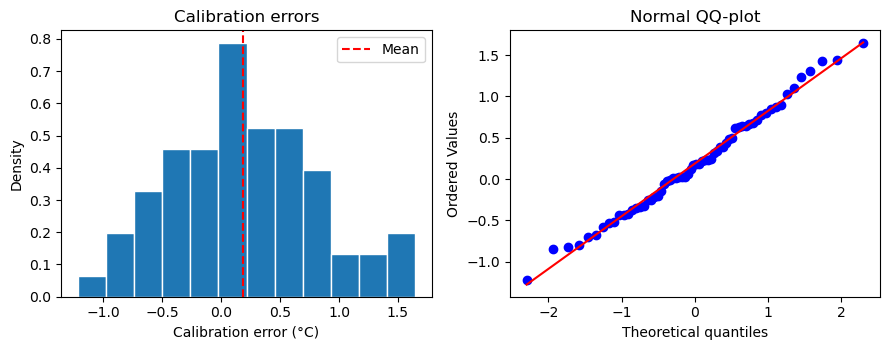

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))

axes[0].set_title("Calibration errors")
axes[0].hist(err, bins=12, density=True, edgecolor="white")
axes[0].axvline(xbar, color="red", linestyle="--", label="Mean")
axes[0].set_xlabel("Calibration error (°C)")
axes[0].set_ylabel("Density")
axes[0].legend()

stats.probplot(err, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ-plot")

plt.tight_layout()
plt.show()

The histogram is roughly symmetric and bell-shaped around $\bar x \approx 0.19$ °C, and the QQ-plot points lie close to the line with only small deviations in the tails. With $n = 64$ the CLT also makes $\bar X$ approximately normal even if the errors are not exactly normal, so a one-sample $t$ interval is reasonable.

Plots only show the **shape** of the values, not how they were collected. Sensors from the same batch, or measured in the same session, could have related errors and the plots would look the same. Independence must come from the study design (independently selected sensors).

### c) Construct a 95% $t$ interval by calculating the degrees of freedom, critical value, standard error, and margin of error. Verify it with SciPy and interpret both the interval and the 95% confidence level correctly.

In [5]:
df = n_e - 1
t_crit = stats.t.ppf(0.975, df)
moe = t_crit * se
ci_95 = (xbar - moe, xbar + moe)

ci_scipy = stats.t.interval(0.95, df=df, loc=xbar, scale=se)

display(Markdown(f'''
$df = n - 1 = {df}$ \\
$t_{{{df},\\,0.975}} = {t_crit:.4f}$ \\
$SE = {se:.4f}$ \\
$E = t \\cdot SE = {t_crit:.4f} \\cdot {se:.4f} = {moe:.4f}$ \\
95% CI $= \\bar x \\pm E = {xbar:.4f} \\pm {moe:.4f} = ({ci_95[0]:.4f}, {ci_95[1]:.4f})$ \\
SciPy: $({ci_scipy[0]:.4f}, {ci_scipy[1]:.4f})$
'''))


$df = n - 1 = 63$ \
$t_{63,\,0.975} = 1.9983$ \
$SE = 0.0782$ \
$E = t \cdot SE = 1.9983 \cdot 0.0782 = 0.1563$ \
95% CI $= \bar x \pm E = 0.1883 \pm 0.1563 = (0.0320, 0.3446)$ \
SciPy: $(0.0320, 0.3446)$


The manual calculation and SciPy give the same interval. We use $t$ instead of $z$ because the population $\sigma$ is unknown and is estimated by $s$.

**Interval:** we are 95% confident that the true mean calibration error $\mu$ of all such sensors is between about 0.03 and 0.34 °C. The whole interval is above 0, which suggests the sensors read slightly too high on average.

**95% confidence level:** if we repeated the study many times with new samples of 64 sensors, about 95% of the intervals built this way would contain $\mu$. It does **not** mean there is a 95% probability that $\mu$ is in this specific interval, since $\mu$ is fixed and either is or is not inside it.

### d) Create a table of 90%, 95%, and 99% $t$ intervals and widths. Explain the confidence–precision trade-off.

In [6]:
to_print = "| confidence | t | low | high | width |\n| -------: | ---: | ---: | ---: | ---: |\n"
for conf in [0.90, 0.95, 0.99]:
    t_c = stats.t.ppf(1 - (1 - conf) / 2, df)
    (low, high) = stats.t.interval(conf, df=df, loc=xbar, scale=se)
    to_print += f"| {conf:.0%} | {t_c:.4f} | {low:.4f} | {high:.4f} | {high - low:.4f} |\n"
display(Markdown(to_print))

| confidence | t | low | high | width |
| -------: | ---: | ---: | ---: | ---: |
| 90% | 1.6694 | 0.0577 | 0.3188 | 0.2612 |
| 95% | 1.9983 | 0.0320 | 0.3446 | 0.3126 |
| 99% | 2.6561 | -0.0195 | 0.3960 | 0.4155 |


Higher confidence needs a larger critical value, so the interval gets wider: from about 0.26 °C at 90% to 0.42 °C at 99%. More confidence means less precision. The only way to get both higher confidence and a narrower interval is a larger sample, which makes the SE smaller.

### e) Using $s$ as a planning value and the normal critical value, find the smallest approximate sample size for a 95% margin of error no larger than $0.10$ °C.

In [7]:
E_target = 0.10
z = stats.norm.ppf(0.975)
n_exact = (z * s / E_target) ** 2
n_plan = math.ceil(n_exact)

display(Markdown(f'''
$n = \\left(\\dfrac{{z \\cdot s}}{{E}}\\right)^2 = \\left(\\dfrac{{{z:.4f} \\cdot {s:.4f}}}{{{E_target:.2f}}}\\right)^2 = {n_exact:.2f}$ \\
Rounded up: $n = {n_plan}$ sensors
'''))


$n = \left(\dfrac{z \cdot s}{E}\right)^2 = \left(\dfrac{1.9600 \cdot 0.6257}{0.1}\right)^2 = 150.42$ \
Rounded up: $n = 151$ sensors


We round up because a smaller $n$ would give a margin slightly above 0.10 °C. The result is approximate: it uses $s$ from this sample as a guess for $\sigma$ and $z$ instead of $t$.

### f) With seed 2026 and at least 10,000 resamples, construct a percentile bootstrap interval. Compare it with the $t$ interval and state what the comparison cannot validate.

In [8]:
rng = np.random.default_rng(2026)
B = 10_000
boot_means = rng.choice(err.to_numpy(), size=(B, n_e), replace=True).mean(axis=1)
boot_ci = np.percentile(boot_means, [2.5, 97.5])

display(Markdown(f'''
| interval | low | high | width |
| -------: | ---: | ---: | ---: |
| 95% $t$ | {ci_95[0]:.4f} | {ci_95[1]:.4f} | {ci_95[1] - ci_95[0]:.4f} |
| 95% bootstrap | {boot_ci[0]:.4f} | {boot_ci[1]:.4f} | {boot_ci[1] - boot_ci[0]:.4f} |

Bootstrap SD of the means $= {boot_means.std(ddof=1):.4f}$ (vs $SE = {se:.4f}$)
'''))


| interval | low | high | width |
| -------: | ---: | ---: | ---: |
| 95% $t$ | 0.0320 | 0.3446 | 0.3126 |
| 95% bootstrap | 0.0408 | 0.3413 | 0.3005 |

Bootstrap SD of the means $= 0.0768$ (vs $SE = 0.0782$)


The bootstrap resamples the 64 sensors with replacement 10,000 times and takes the middle 95% of the resampled means. It gives almost the same interval as the $t$ interval, and its SD of means is close to the SE. This supports the $t$ interval's normal approximation for $\bar X$.

The comparison **cannot** validate how the data was collected. Both methods assume the 64 sensors are an independent, representative sample of the population. If sensors are dependent, come from one batch, or the reference temperature is biased, both intervals are wrong in the same way, and agreeing with each other does not reveal it.

# Part 3 — Estimating a false-rejection proportion
#### The file assignment03_access_control.csv contains 240 independently staged legitimate login attempts. false_reject equals 1 when a legitimate attempt was rejected and 0 otherwise. Let $p$ be the population false-rejection probability under the test conditions.

In [9]:
ac = pd.read_csv("assignment03_access_control.csv")
ac.head(5)

,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


### a) Report $n$, the number of false rejections $x$, and $\hat p$. Explain why $\hat p$ is also the sample mean of a binary variable.

In [10]:
n = len(ac)
x = ac['false_reject'].sum()
p_hat = x / n

display(Markdown(f"""
$n = {n}$ \\
$x = {x}$ \\
$\\hat p = {p_hat}$ \\
$\\hat p$ is equal to a sample mean of a binary variable since its values are only zeros or ones, so adding up all values is the same as counting the number of occurances of 1's
# """))


$n = 240$ \
$x = 20$ \
$\hat p = 0.08333333333333333$ \
$\hat p$ is equal to a sample mean of a binary variable since its values are only zeros or ones, so adding up all values is the same as counting the number of occurances of 1's
# 

### b) Construct and interpret a 95% Wilson interval for $p$ with statsmodels. State the population and parameter clearly.

In [11]:
wilson = proportion_confint(count=x, nobs=n, alpha=0.05, method='wilson')
display(Markdown(f"""
95% wilson = {tuple(np.round(wilson, 4))} \\
The population would be all legitimate login attempts, while the parameter is the true probability of getting a false reject which, due to the wilson interval, we are 95% sure is between 0.055 and 0.125
"""))


95% wilson = (0.0546, 0.1252) \
The population would be all legitimate login attempts, while the parameter is the true probability of getting a false reject which, due to the wilson interval, we are 95% sure is between 0.055 and 0.125


### c) Calculate the 95% Wald interval from its formula. Compare it with Wilson and explain why Wilson is the preferred default.

In [12]:
wald_se = np.sqrt(p_hat * (1 - p_hat) / n)
z = stats.norm.ppf(0.975)
wald = (p_hat - z * wald_se, p_hat + z * wald_se)
display(Markdown(f"""
95% wald vs 95% wilson \\
{tuple(np.round(wald, 4))} &emsp; {tuple(np.round(wilson, 4))} \\
Wilson is preferable as wald requires a large sample size
"""))


95% wald vs 95% wilson \
(0.0484, 0.1183) &emsp; (0.0546, 0.1252) \
Wilson is preferable as wald requires a large sample size


### d) Create a table of 90%, 95%, and 99% Wilson intervals and widths.

In [13]:
to_print = "|wilson | low | high | width | \n| -------: | ---: | ---: | ---: |\n"
for alp in [0.1, 0.05, 0.01]:
    (w_low, w_high) = proportion_confint(count=x, nobs=n, alpha=alp, method='wilson')
    to_print += f"|{1 - alp} | {round(w_low, 4)} | {round(w_high, 4)}| {round((w_high - w_low) ,4 )} | \n"
display(Markdown(to_print))

|wilson | low | high | width | 
| -------: | ---: | ---: | ---: |
|0.9 | 0.0584 | 0.1175| 0.0591 | 
|0.95 | 0.0546 | 0.1252| 0.0706 | 
|0.99 | 0.0478 | 0.1412| 0.0934 | 


### e) Estimate the sample size for a 95% margin of error no larger than 0.02 using $p = 0.5$ first and then the $\hat p$ observed. Round up and explain the difference.

In [14]:
def stupid_sample_search(p):
    for x in range(1, 10000):
        wald_se = np.sqrt(p * (1 - p) / x)
        z_crit = stats.norm.ppf(0.975)
        moe = wald_se * z_crit
        if (moe < 0.02):
            return x

display(Markdown(f"""
The sample size required for a 95% MOE no larger than 0.02 for p=0.5 is {stupid_sample_search(0.5)} \\
While for the actual observed $\\hat p = {p_hat}$ it is {stupid_sample_search(p_hat)} \\
The difference would come from the fact that $0.5 \\neq {p_hat}$
"""))


The sample size required for a 95% MOE no larger than 0.02 for p=0.5 is 2401 \
While for the actual observed $\hat p = 0.08333333333333333$ it is 734 \
The difference would come from the fact that $0.5 \neq 0.08333333333333333$


# Part 4 — AI-use and conclusion